# Prediction errors: from conditioning to actor–critic

Supervised learning needs a teacher who knows the right answer. Animals rarely get one. They get
rewards, often delayed, and must work out which of their earlier experiences and actions
predicted them. **Reinforcement learning** formalises this, and its central quantity, the
*reward prediction error*, turned out to be signalled by midbrain dopamine neurons.

The parts of an RL problem:

- a **policy**: which action to take in each state;
- a **reward** signal: what is good right now;
- a **value function**: how much reward to expect from a state onwards;
- optionally, a **model** of the environment for planning.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
rng = np.random.default_rng(0)

## Rescorla–Wagner: learning from surprise

In classical conditioning a cue (a bell) comes to predict an outcome (food). Rescorla and
Wagner (1972) proposed that the associative strength $V$ changes in proportion to the
**prediction error**:

$$V \leftarrow V + \alpha\,(r - V).$$

With several cues present, the prediction is the sum of their strengths, $\hat r = \sum_j V_j$,
and every present cue is updated by the same shared error. This is the delta rule from notebook
6 with cues as inputs.

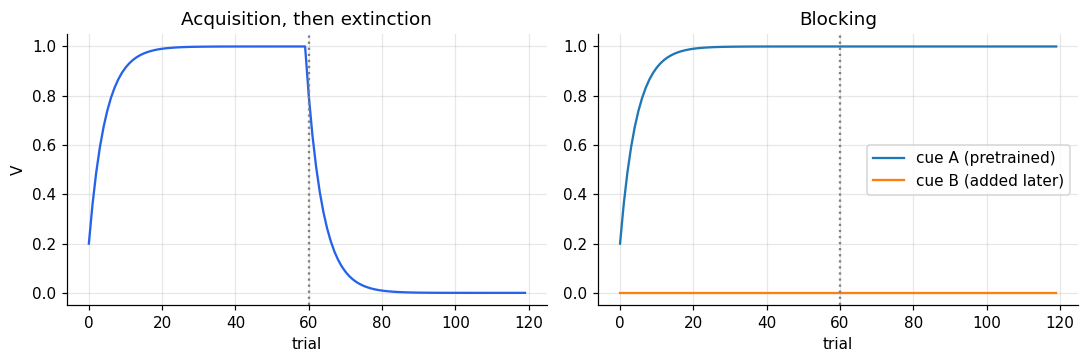

In [2]:
def rescorla_wagner(cues, rewards, alpha=0.2):
    V = np.zeros(cues.shape[1])
    history = []
    for x, r in zip(cues, rewards):
        delta = r - x @ V
        V = V + alpha * delta * x
        history.append(V.copy())
    return np.array(history)

n = 60
# acquisition then extinction for a single cue
cues = np.ones((2 * n, 1))
rewards = np.r_[np.ones(n), np.zeros(n)]
h_single = rescorla_wagner(cues, rewards)

# blocking: A alone is rewarded, then A+B together
cues_block = np.r_[np.tile([1, 0], (n, 1)), np.tile([1, 1], (n, 1))]
h_block = rescorla_wagner(cues_block, np.ones(2 * n))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(h_single[:, 0], color="#2563eb")
axes[0].axvline(n, color="grey", ls=":")
axes[0].set(title="Acquisition, then extinction", xlabel="trial", ylabel="V")
axes[1].plot(h_block[:, 0], label="cue A (pretrained)")
axes[1].plot(h_block[:, 1], label="cue B (added later)")
axes[1].axvline(n, color="grey", ls=":")
axes[1].set(title="Blocking", xlabel="trial")
axes[1].legend()
plt.tight_layout()
plt.show()

**Blocking** (Kamin, 1969) is the model's signature prediction. Once cue A fully predicts the
reward there is no error left, so cue B, though paired with reward on every trial, learns
nothing. Learning is driven by surprise, not by co-occurrence, which is the key difference from
Hebbian learning.

## Predicting the future: temporal-difference learning

Rescorla–Wagner treats a trial as one moment. In reality a cue comes first and reward later, and
the goal is to predict the total future reward from each moment,

$$V(t) = \mathbb E\Big[\sum_{\tau \ge 0} \gamma^\tau r(t + \tau)\Big].$$

This obeys a recursion: $V(t) = r(t) + \gamma V(t+1)$. **Temporal-difference (TD) learning**
(Sutton, 1988) uses the mismatch in that recursion as its error,

$$\delta(t) = r(t) + \gamma V(t+1) - V(t),$$

and updates the value of the current moment: $V(t) \leftarrow V(t) + \alpha\,\delta(t)$. No
need to wait for the future to arrive: each prediction is corrected by the next one.

To predict *when* reward arrives the model needs to know how much time has passed since the
cue. The simplest assumption, the *complete serial compound*, gives each time step after the
cue its own feature, like a tapped delay line.

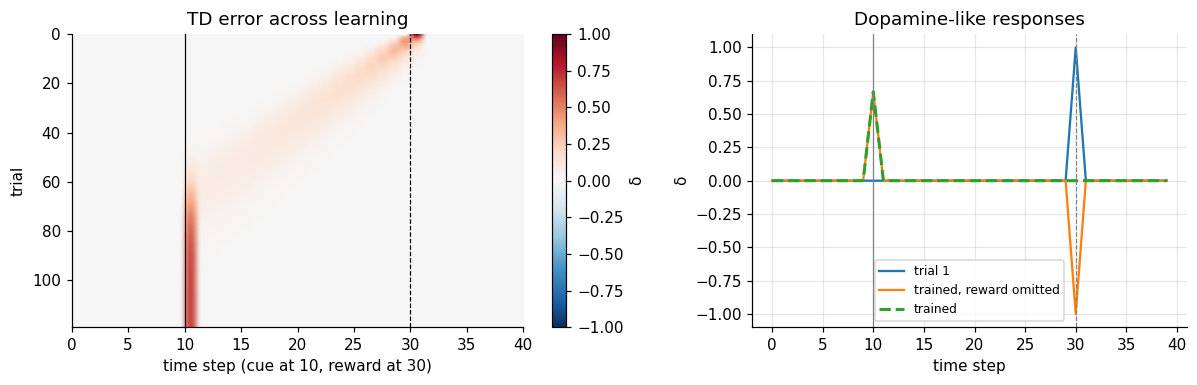

In [3]:
T, cue_t, reward_t = 40, 10, 30
gamma, alpha, n_trials = 0.98, 0.3, 120

def run_td(n_trials, omit_on=()):
    # Feature k is active k steps after the cue; nothing is active before the cue, so the value
    # of pre-cue moments stays at zero and the cue itself is unpredicted.
    x = np.zeros((T, T))
    for t in range(cue_t, T):
        x[t, t - cue_t] = 1.0
    w = np.zeros(T)
    deltas = np.zeros((n_trials, T))
    for trial in range(n_trials):
        r = np.zeros(T)
        if trial not in omit_on:
            r[reward_t] = 1.0
        for t in range(T - 1):
            delta = r[t + 1] + gamma * (x[t + 1] @ w) - x[t] @ w
            deltas[trial, t + 1] = delta      # error on entering moment t + 1
            w += alpha * delta * x[t]
    return deltas

deltas = run_td(n_trials, omit_on={n_trials - 1})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
im = axes[0].imshow(deltas[:-1], aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1,
                    extent=[0, T, n_trials - 1, 0])
axes[0].axvline(cue_t, color="k", lw=0.8)
axes[0].axvline(reward_t, color="k", lw=0.8, ls="--")
axes[0].set(xlabel="time step (cue at 10, reward at 30)", ylabel="trial",
            title="TD error across learning")
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], label="δ")
for trial, lab, style in [(0, "trial 1", "-"), (n_trials - 1, "trained, reward omitted", "-"),
                          (n_trials - 2, "trained", "--")]:
    axes[1].plot(deltas[trial], ls=style, lw=2 if style == "--" else 1.5, label=lab)
axes[1].axvline(cue_t, color="grey", lw=0.8)
axes[1].axvline(reward_t, color="grey", lw=0.8, ls="--")
axes[1].set(xlabel="time step", ylabel="δ", title="Dopamine-like responses")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

Early in learning, the error appears at the reward. As the value of the intervening moments is
learned, the error moves back step by step until, after training, it appears at the **cue**,
the first reliable predictor of reward, and has vanished at the reward itself. Omitting the
reward on a trained trial gives a **dip** at exactly the time reward was due.

This is precisely what Schultz, Dayan and Montague (1997) found in dopamine neurons of the
monkey ventral tegmental area. The dip on omission also shows that the system has learned *when*
reward is due, not just whether. That depends on the time representation: with a tapped delay
line timing is perfect, which real animals' timing is not. Replacing it with representations
that grow fuzzier with elapsed time (for example *microstimuli*, Ludvig, Sutton & Kehoe, 2008)
connects TD learning to the scalar variability of interval timing.

## Values of states: a rat in a barn

Now let the agent move. A rat starts at A and turns left or right, reaching B or C; there it
turns again and receives a reward.

```text
           A
         /   \
        B     C
       / \   / \
      0   5 2   0
```

Under a **random policy** (each turn left or right with probability 0.5) the true values are
$v(B) = 0.5\cdot0 + 0.5\cdot5 = 2.5$, $v(C) = 0.5\cdot2 + 0.5\cdot0 = 1$, and
$v(A) = 0.5\,v(B) + 0.5\,v(C) = 1.75$. TD learning should find them from experience alone.

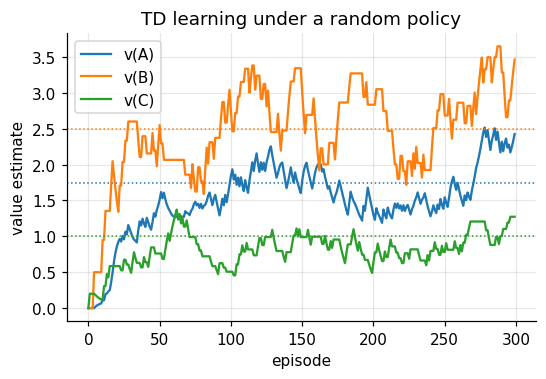

In [4]:
maze = {"A": {"L": ("B", 0.0), "R": ("C", 0.0)},
        "B": {"L": (None, 0.0), "R": (None, 5.0)},
        "C": {"L": (None, 2.0), "R": (None, 0.0)}}

def td_policy_evaluation(n_episodes=300, alpha=0.1):
    v = {"A": 0.0, "B": 0.0, "C": 0.0}
    trace = []
    for _ in range(n_episodes):
        s = "A"
        while s is not None:
            a = rng.choice(["L", "R"])
            s_next, r = maze[s][a]
            v_next = v[s_next] if s_next else 0.0
            v[s] += alpha * (r + v_next - v[s])
            s = s_next
        trace.append(dict(v))
    return trace

trace = td_policy_evaluation()
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for s, true in [("A", 1.75), ("B", 2.5), ("C", 1.0)]:
    line, = ax.plot([t[s] for t in trace], label=f"v({s})")
    ax.axhline(true, color=line.get_color(), ls=":", lw=1)
ax.set(xlabel="episode", ylabel="value estimate", title="TD learning under a random policy")
ax.legend()
plt.show()

The estimates converge to the true values (dotted) and keep fluctuating around them, because
with a constant learning rate every new random reward nudges them.

## Learning to act: actor–critic

Knowing values is not the same as acting well. In an **actor–critic** architecture two systems
share one error signal:

- the **critic** learns state values with TD, $v(s) \leftarrow v(s) + \alpha_c\,\delta$;
- the **actor** keeps a preference $m(s, a)$ for each action and chooses by softmax,
  $P(a \mid s) = \dfrac{e^{\beta m(s,a)}}{\sum_b e^{\beta m(s,b)}}$, where the inverse
  temperature $\beta$ trades exploitation against exploration;
- after each step, the action just taken is reinforced if the outcome was better than the
  critic expected: $m(s, a) \leftarrow m(s, a) + \alpha_a\,\delta$.

The critic and actor are often mapped onto ventral and dorsal striatum, with dopamine
broadcasting $\delta$ to both.

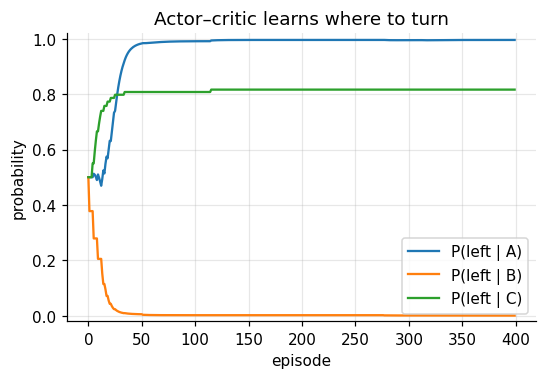

final critic values: {'A': 5.0, 'B': 5.0, 'C': 1.49}


In [5]:
def actor_critic(n_episodes=400, alpha_c=0.1, alpha_a=0.1, beta=1.0):
    v = {s: 0.0 for s in maze}
    m = {s: {"L": 0.0, "R": 0.0} for s in maze}
    p_trace = []
    for _ in range(n_episodes):
        s = "A"
        while s is not None:
            prefs = np.array([m[s]["L"], m[s]["R"]])
            p = np.exp(beta * prefs) / np.exp(beta * prefs).sum()
            a = "L" if rng.random() < p[0] else "R"
            s_next, r = maze[s][a]
            delta = r + (v[s_next] if s_next else 0.0) - v[s]
            v[s] += alpha_c * delta
            m[s][a] += alpha_a * delta
            s = s_next
        p_trace.append({s: 1 / (1 + np.exp(-beta * (m[s]["L"] - m[s]["R"]))) for s in maze})
    return p_trace, v

p_trace, v_final = actor_critic()
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for s in maze:
    ax.plot([p[s] for p in p_trace], label=f"P(left | {s})")
ax.set(xlabel="episode", ylabel="probability", ylim=(-0.02, 1.02),
       title="Actor–critic learns where to turn")
ax.legend()
plt.show()
print("final critic values:", {s: round(x, 2) for s, x in v_final.items()})

The agent learns to turn left at A and right at B, the route to the large reward. As the policy
improves, the critic's values rise from the random-policy values towards those of the good
policy ($v(A)$ and $v(B)$ approach 5). At C the agent should turn left, but because it rarely
visits C once it prefers B, that preference is learned slowly: what an agent knows depends on
where its own policy takes it.

## Summary

- Rescorla–Wagner learning is driven by prediction error and explains blocking.
- TD learning predicts future reward and corrects each prediction with the next one.
- TD errors move from reward to the earliest predictive cue and dip on omission, like dopamine
  neurons; this requires a representation of elapsed time.
- TD learning estimates state values from experience; an actor–critic uses the same error to
  improve its policy.